In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score,adjusted_rand_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
X,y_true=make_blobs(n_samples=1500,n_features=4,centers=4,cluster_std=[1.0,1.5,0.8,2.0],random_state=7)
df=pd.DataFrame(X,columns=['f1','f2','f3','f4'])
print(df.shape)
df.describe().round(2)

(1500, 4)


,f1,f2,f3,f4
count,1500.00,1500.00,1500.00,1500.00
mean,-1.51,-0.58,-0.44,2.46
std,6.81,5.28,3.11,6.64
min,-10.78,-15.15,-9.55,-12.58
25%,-6.59,-3.86,-2.35,-0.05
50%,-3.98,0.28,-0.61,5.20
75%,3.68,3.59,2.24,6.64
max,13.95,8.19,5.76,14.10


In [3]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

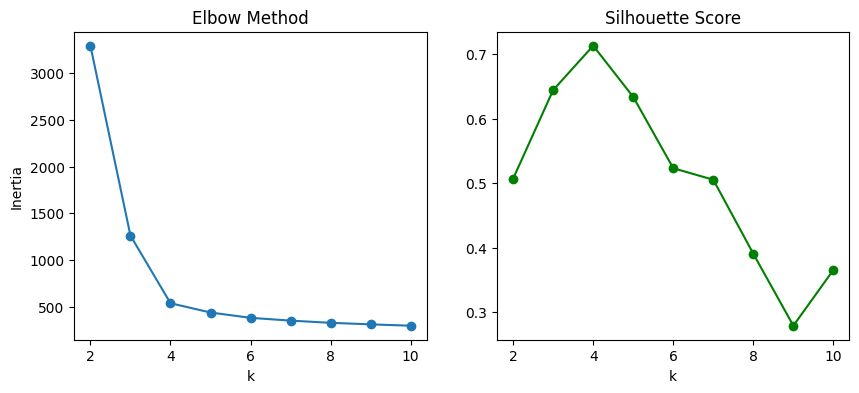

In [4]:
ks=range(2,11)
inertias=[]
sil=[]
for k in ks:
    km=KMeans(n_clusters=k,n_init=10,random_state=7).fit(X_scaled)
    inertias.append(km.inertia_)
    sil.append(silhouette_score(X_scaled,km.labels_))

fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].plot(ks,inertias,'o-')
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inertia")
ax[1].plot(ks,sil,'o-',color='green')
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("k")
plt.show()

In [5]:
model=KMeans(n_clusters=4,n_init=10,random_state=7)
model.fit(X_scaled)
labels=model.labels_
df['cluster']=labels
print(df['cluster'].value_counts().sort_index())

cluster
0    377
1    375
2    373
3    375
Name: count, dtype: int64


In [6]:
print('Silhouette score  :',silhouette_score(X_scaled,labels))
print('Inertia           :',model.inertia_)
print('Adjusted Rand idx :',adjusted_rand_score(y_true,labels))

Silhouette score  : 0.7131728042202224
Inertia           : 539.6531078837538
Adjusted Rand idx : 0.9964468317270232


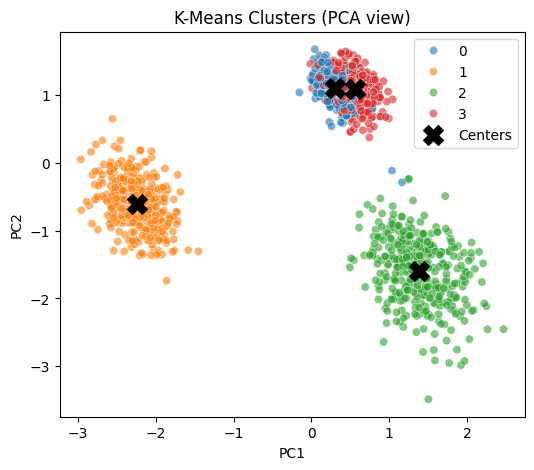

In [7]:
pca=PCA(n_components=2)
X_2d=pca.fit_transform(X_scaled)
centers_2d=pca.transform(model.cluster_centers_)
plt.figure(figsize=(6,5))
sns.scatterplot(x=X_2d[:,0],y=X_2d[:,1],hue=labels,palette='tab10',alpha=0.6)
plt.scatter(centers_2d[:,0],centers_2d[:,1],c='black',marker='X',s=200,label='Centers')
plt.title("K-Means Clusters (PCA view)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

In [8]:
new_sample=np.array([[2.0,-6.0,5.0,1.0],[-8.0,3.0,-2.0,7.0],[0.0,0.0,0.0,0.0]],ndmin=2)
new_cluster=model.predict(scaler.transform(new_sample))
print(f'the sample clusters are {new_cluster}')

the sample clusters are [0 3 0]
